In [1]:
import torch
from model.torch_hub_models import Hub_Model
from model.CNN import Custom_CNN
from torch.utils.data import DataLoader
from dataset import LoadDataAndLabel
from tqdm import tqdm
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

In [2]:
import yaml

def load_config(file_path='config_infer.yaml'):
    with open(file_path, 'r') as file:
        config = yaml.safe_load(file)
    return config

# Load configuration
config = load_config()

In [3]:
# Extracting the values from the config
model_configs = config['model']
task = model_configs['task']
model_type = model_configs['type']
length = model_configs['length']
sr = model_configs['sampling_rate']
n_mels = model_configs['n_mels']
n_fft, window_len, step_size = model_configs['window_configs'][sr]
checkpoint = model_configs.get('checkpoint')

In [4]:
datasets = config['datasets']['paths']
datasets

['dataset/noisy_testset.txt', 'dataset/clean_testset.txt']

In [5]:
if task == "gender":
    n_classes = 2
elif task == "dialect":
    n_classes = 3
else:
    raise ValueError(f"Unsupported task type: {task}. Valid options are 'gender' or 'dialect'.")

In [6]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

if model_type == 'CNN':
    # Use the custom CNN-based model
    model = Custom_CNN(
        n_classes=n_classes,
        n_mels=n_mels,
        sampling_rate=sr,
        n_fft=n_fft,
        window=window_len,
        step=step_size
    ).to(device)
else:
    # Use the Model with a pretrained backbone
    try:
        model = Hub_Model(
            n_classes=n_classes,
            n_mels=n_mels,
            sampling_rate=sr,
            n_fft=n_fft,
            window=window_len,
            step=step_size,
            model_type=model_type,
            version=model_configs['versions'][model_type]
        ).to(device)
    except Exception as e:
        raise RuntimeError(f"Failed to load model '{model_type}' from PyTorch Hub: {e}")

In [7]:
from pathlib import Path

if not checkpoint or not Path(checkpoint).is_file():
    raise FileNotFoundError(f"Checkpoint does not exist: {checkpoint}")
state_dict = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(state_dict, strict=True)
model.eval()
print(f"Task: {task} | Model: {model_type} | Device: {device}")
print(f"Checkpoint: {checkpoint}")


Task: dialect | Model: resnet34 | Device: cuda:0
Checkpoint: checkpoints/dialect/resnet34_20261010_213509/best_1.pth


In [8]:
def evaluate_model(model, loader_eval, dataset_name):

    model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for data, target in tqdm(loader_eval, desc=dataset_name):
            outputs = model(data.to(device))
            y_pred.extend(outputs.argmax(dim=1).cpu().tolist())
            y_true.extend(target.cpu().tolist())

    if not y_true:
        raise ValueError(f"Empty evaluation dataset: {dataset_name}")

    labels = list(range(n_classes))
    class_names = ['female', 'male'] if task == 'gender' else ['north', 'central', 'south']
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0)
    _, _, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average='macro', zero_division=0)

    print(f"Accuracy: {accuracy:.4f} | Macro-F1: {macro_f1:.4f}")
    for idx, name in enumerate(class_names):
        print(f"{name}: precision={precision[idx]:.4f}, recall={recall[idx]:.4f}, "
              f"F1={f1[idx]:.4f}, support={support[idx]}")

    print("Confusion matrix (rows=true, columns=predicted):")
    print(cm)
    try:
        import matplotlib.pyplot as plt
        from sklearn.metrics import ConfusionMatrixDisplay
    except ImportError:
        print("Plot skipped: install matplotlib in the notebook kernel to display the chart.")
    else:
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'Confusion Matrix ? {Path(dataset_name).stem}')
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    return {'dataset': dataset_name, 'accuracy': accuracy, 'macro_f1': macro_f1,
            'precision': precision, 'recall': recall, 'f1': f1, 'support': support,
            'confusion_matrix': cm, 'y_true': y_true, 'y_pred': y_pred}



------Evaluating dataset/noisy_testset.txt...


dataset/noisy_testset.txt: 100%|██████████| 32/32 [00:11<00:00,  2.71it/s]


Accuracy: 0.7539 | Macro-F1: 0.7527
north: precision=0.7778, recall=0.7206, F1=0.7481, support=340
central: precision=0.7218, recall=0.8471, F1=0.7794, support=340
south: precision=0.7712, recall=0.6941, F1=0.7307, support=340
Confusion matrix (rows=true, columns=predicted):
[[245  48  47]
 [ 29 288  23]
 [ 41  63 236]]


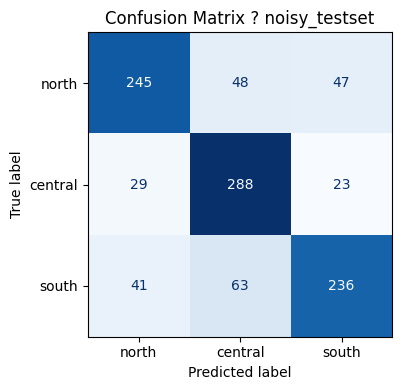


------Evaluating dataset/clean_testset.txt...


dataset/clean_testset.txt: 100%|██████████| 47/47 [00:13<00:00,  3.61it/s]

Accuracy: 0.8060 | Macro-F1: 0.8059
north: precision=0.8247, recall=0.8280, F1=0.8263, support=500
central: precision=0.8123, recall=0.8220, F1=0.8171, support=500
south: precision=0.7805, recall=0.7680, F1=0.7742, support=500
Confusion matrix (rows=true, columns=predicted):
[[414  40  46]
 [ 27 411  62]
 [ 61  55 384]]


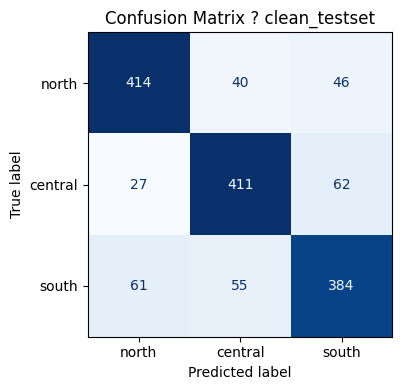

In [9]:
results = {}
for dataset_path in datasets:
    print(f"\n------Evaluating {dataset_path}...")
    eval_dataset = LoadDataAndLabel(
        dataset=dataset_path,
        audio_length=length,
        sampling_rate=sr,
        window_len=window_len,
        step_size=step_size,
        task_type=task,
        enable_augmentation=False,
    )
    # Use the main process for reliable execution in Windows notebooks.
    eval_loader = DataLoader(eval_dataset, batch_size=32, num_workers=0, shuffle=False)
    results[dataset_path] = evaluate_model(model, eval_loader, dataset_path)
